<a href="https://colab.research.google.com/github/Shreyaslad99/Deepfake-Detector/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q huggingface_hub

import os, zipfile, glob, subprocess

DATA_DIR = "/content/data"
ZIP_PATH = f"{DATA_DIR}/MachineLearningCSV.zip"
os.makedirs(DATA_DIR, exist_ok=True)

def from_huggingface():
    from huggingface_hub import list_repo_files, hf_hub_download
    repo = "bencorn/CICIDS2017"
    names = [f for f in list_repo_files(repo, repo_type="dataset")
             if f.endswith("MachineLearningCSV.zip")]
    if not names:
        raise FileNotFoundError("zip not found in HF repo")
    p = hf_hub_download(repo_id=repo, repo_type="dataset",
                        filename=names[0], local_dir=DATA_DIR)
    return p

def from_direct_url():
    # Older direct link to the original server (may be down or moved)
    url = "http://205.174.165.80/CICDataset/CIC-IDS-2017/Dataset/MachineLearningCSV.zip"
    subprocess.run(["wget", "-q", "-O", ZIP_PATH, url], check=True)
    return ZIP_PATH

path = None
for name, fn in [("Hugging Face", from_huggingface), ("Direct URL", from_direct_url)]:
    try:
        print(f"Trying {name} ...")
        path = fn()
        if zipfile.is_zipfile(path):
            print(f"Downloaded via {name}: {path}")
            break
        path = None
    except Exception as e:
        print(f"{name} failed: {e}")

if path is None:
    raise SystemExit("Both downloads failed. Use the manual upload option.")

with zipfile.ZipFile(path) as z:
    z.extractall(DATA_DIR)

csvs = sorted(glob.glob(f"{DATA_DIR}/**/*.csv", recursive=True))
print(f"\n{len(csvs)} CSV files:")
for f in csvs:
    print(" ", os.path.basename(f), f"{os.path.getsize(f)/1e6:.0f} MB")

Trying Hugging Face ...


csvs/MachineLearningCSV.zip: reconstructing file:   0%|          |  0.00B /  235MB            

csvs/MachineLearningCSV.zip: downloading bytes:           |  0.00B            

Downloaded via Hugging Face: /content/data/csvs/MachineLearningCSV.zip

8 CSV files:
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv 77 MB
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv 77 MB
  Friday-WorkingHours-Morning.pcap_ISCX.csv 58 MB
  Monday-WorkingHours.pcap_ISCX.csv 177 MB
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv 83 MB
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv 52 MB
  Tuesday-WorkingHours.pcap_ISCX.csv 135 MB
  Wednesday-workingHours.pcap_ISCX.csv 225 MB


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import zipfile
with zipfile.ZipFile("/content/drive/MyDrive/MachineLearningCSV.zip") as z:
    z.extractall("/content/data")

Mounted at /content/drive


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MachineLearningCSV.zip'

In [3]:
import os, glob
import numpy as np
import pandas as pd

csvs = sorted(glob.glob("/content/data/**/*.csv", recursive=True))

frames = []
for f in csvs:
    df = pd.read_csv(f, encoding="cp1252", low_memory=False)
    df.columns = df.columns.str.strip()            # column names have leading spaces
    df["day"] = os.path.basename(f).split("-")[0]  # Monday, Tuesday, ...
    frames.append(df)
    print(os.path.basename(f), df.shape)

data = pd.concat(frames, ignore_index=True)
del frames
print("\nRaw shape:", data.shape)

# 1. Drop the duplicated column if present
if "Fwd Header Length.1" in data.columns:
    data = data.drop(columns=["Fwd Header Length.1"])

# 2. Fix weird characters in labels (e.g. 'Web Attack � Brute Force')
data["Label"] = (data["Label"]
                 .str.replace(r"[^\x00-\x7F]+", "-", regex=True)
                 .str.replace(r"\s*-\s*", " - ", regex=True)
                 .str.strip())

# 3. Features -> float32, replace inf with NaN, drop NaN rows
feat_cols = [c for c in data.columns if c not in ("Label", "day")]
data[feat_cols] = (data[feat_cols]
                   .replace([np.inf, -np.inf], np.nan)
                   .astype("float32"))
before = len(data)
data = data.dropna().reset_index(drop=True)
print("Dropped NaN/Inf rows:", before - len(data))

# 4. Drop duplicate rows
before = len(data)
data = data.drop_duplicates(subset=feat_cols + ["Label"]).reset_index(drop=True)
print("Dropped duplicates:", before - len(data))

print("Clean shape:", data.shape)

# Save so you don't redo this if Colab restarts
data.to_parquet("/content/data/cicids_clean.parquet")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (225745, 80)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (286467, 80)
Friday-WorkingHours-Morning.pcap_ISCX.csv (191033, 80)
Monday-WorkingHours.pcap_ISCX.csv (529918, 80)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (288602, 80)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (170366, 80)
Tuesday-WorkingHours.pcap_ISCX.csv (445909, 80)
Wednesday-workingHours.pcap_ISCX.csv (692703, 80)

Raw shape: (2830743, 80)
Dropped NaN/Inf rows: 2867
Dropped duplicates: 329896
Clean shape: (2497980, 79)


In [4]:
print(data["Label"].value_counts())
print()
print(pd.crosstab(data["Label"], data["day"]))

Label
BENIGN                        2072254
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10282
FTP - Patator                    5931
DoS slowloris                    5374
DoS Slowhttptest                 5228
SSH - Patator                    3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

day                         Friday  Monday  Thursday  Tuesday  Wednesday
Label                                                                   
BENIGN                      394764  492605    394718   397317     392850
Bot                           1948       0         0        0          0
DDoS                        128014       0         0        0          0
DoS GoldenEye                   

In [5]:
import numpy as np, pandas as pd

# reload only if the session restarted
if "data" not in globals():
    data = pd.read_parquet("/content/data/cicids_clean.parquet")

label_map = {
    "BENIGN": "BENIGN",
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS",
    "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
    "DDoS": "DDoS", "PortScan": "PortScan",
    "FTP - Patator": "BruteForce", "SSH - Patator": "BruteForce",
    "Web Attack - Brute Force": "WebAttack",
    "Web Attack - XSS": "WebAttack",
    "Web Attack - Sql Injection": "WebAttack",
    "Bot": "Bot",
}   # Heartbleed and Infiltration are intentionally left out (dropped)

classes = ["BENIGN", "DoS", "DDoS", "PortScan", "BruteForce", "WebAttack", "Bot"]
cls2id = {c: i for i, c in enumerate(classes)}

df = data[data["Label"].isin(label_map)].copy()
df["cls"] = df["Label"].map(label_map)
df["y"] = df["cls"].map(cls2id).astype("int64")

print(df["cls"].value_counts())
print("Total rows:", len(df))

cls
BENIGN        2072254
DoS            193730
DDoS           128014
PortScan        90694
BruteForce       9150
WebAttack        2143
Bot              1948
Name: count, dtype: int64
Total rows: 2497933


In [6]:
from sklearn.model_selection import train_test_split

feat_cols = [c for c in df.columns if c not in ("Label", "day", "cls", "y")]
print("Number of features:", len(feat_cols))

X = df[feat_cols].values.astype(np.float32)
y = df["y"].values
day = df["day"].values

# signed log transform (handles negative values)
X = np.sign(X) * np.log1p(np.abs(X))

idx = np.arange(len(df))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=42)

# statistics from TRAIN only
mu = X[tr_idx].mean(axis=0)
sd = X[tr_idx].std(axis=0)
sd[sd < 1e-6] = 1.0

X -= mu
X /= sd
np.clip(X, -10, 10, out=X)

X_train, y_train, day_train = X[tr_idx], y[tr_idx], day[tr_idx]
X_test,  y_test            = X[te_idx], y[te_idx]
print("Train:", X_train.shape, " Test:", X_test.shape)

# save so you can reuse after a restart
import os
os.makedirs("/content/data/prep", exist_ok=True)
for name, arr in dict(X_train=X_train, y_train=y_train, day_train=day_train,
                      X_test=X_test, y_test=y_test).items():
    np.save(f"/content/data/prep/{name}.npy", arr)

Number of features: 77
Train: (1998346, 77)  Test: (499587, 77)


In [7]:
import torch, torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
torch.manual_seed(42); np.random.seed(42)

N_FEAT, N_CLS = X_train.shape[1], len(classes)

def make_model():
    return nn.Sequential(
        nn.Linear(N_FEAT, 128), nn.ReLU(),
        nn.Linear(128, 64), nn.ReLU(),
        nn.Linear(64, N_CLS),
    )

# class weights from train counts
counts = np.bincount(y_train, minlength=N_CLS).astype(np.float64)
w = np.sqrt(counts.sum() / counts)
w = w / w.mean()
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

def train_epoch(model, X, y, opt, bs=1024):
    model.train()
    perm = torch.randperm(len(X), device=X.device)
    total = 0.0
    for i in range(0, len(X), bs):
        b = perm[i:i+bs]
        opt.zero_grad()
        loss = loss_fn(model(X[b]), y[b])
        loss.backward()
        opt.step()
        total += loss.item() * len(b)
    return total / len(X)

@torch.no_grad()
def predict(model, X, bs=8192):
    model.eval()
    out = [model(X[i:i+bs]).argmax(1).cpu() for i in range(0, len(X), bs)]
    return torch.cat(out).numpy()

Xtr = torch.from_numpy(X_train).to(device); ytr = torch.from_numpy(y_train).to(device)
Xte = torch.from_numpy(X_test).to(device)

model = make_model().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

for ep in range(1, 11):
    loss = train_epoch(model, Xtr, ytr, opt)
    pred = predict(model, Xte)
    print(f"epoch {ep:2d}  loss {loss:.4f}  "
          f"acc {accuracy_score(y_test, pred):.4f}  "
          f"macroF1 {f1_score(y_test, pred, average='macro'):.4f}")

# final report
pred = predict(model, Xte)
print(classification_report(y_test, pred, target_names=classes, digits=4))
print(confusion_matrix(y_test, pred))

central_results = {"acc": accuracy_score(y_test, pred),
                   "macro_f1": f1_score(y_test, pred, average="macro")}

Device: cpu
epoch  1  loss 0.0777  acc 0.9938  macroF1 0.8593
epoch  2  loss 0.0247  acc 0.9957  macroF1 0.8711
epoch  3  loss 0.0218  acc 0.9953  macroF1 0.8873
epoch  4  loss 0.0207  acc 0.9959  macroF1 0.8730
epoch  5  loss 0.0192  acc 0.9926  macroF1 0.8681
epoch  6  loss 0.0187  acc 0.9963  macroF1 0.8895
epoch  7  loss 0.0172  acc 0.9973  macroF1 0.9173
epoch  8  loss 0.0158  acc 0.9953  macroF1 0.8741
epoch  9  loss 0.0139  acc 0.9957  macroF1 0.8924
epoch 10  loss 0.0130  acc 0.9961  macroF1 0.8914
              precision    recall  f1-score   support

      BENIGN     0.9999    0.9954    0.9976    414451
         DoS     0.9861    0.9997    0.9929     38746
        DDoS     0.9996    0.9998    0.9997     25603
    PortScan     0.9886    0.9992    0.9939     18139
  BruteForce     0.9657    0.9989    0.9820      1830
   WebAttack     0.7386    0.9814    0.8428       429
         Bot     0.2786    0.9512    0.4310       389

    accuracy                         0.9961    499587


In [8]:
def partition_iid(n, k, seed=0):
    rng = np.random.default_rng(seed)
    return np.array_split(rng.permutation(n), k)

def partition_by_day(day_arr):
    days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
    return [np.where(day_arr == d)[0] for d in days]

def partition_dirichlet(y, k, alpha, seed=0, min_size=50):
    rng = np.random.default_rng(seed)
    while True:
        parts = [[] for _ in range(k)]
        for c in range(N_CLS):
            idx_c = np.where(y == c)[0]
            rng.shuffle(idx_c)
            p = rng.dirichlet([alpha] * k)
            cuts = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
            for i, chunk in enumerate(np.split(idx_c, cuts)):
                parts[i].extend(chunk.tolist())
        if min(len(p) for p in parts) >= min_size:
            break
    return [np.array(p) for p in parts]

def show_partition(parts, name):
    tab = pd.DataFrame([np.bincount(y_train[p], minlength=N_CLS) for p in parts],
                       columns=classes)
    tab.index = [f"client{i}" for i in range(len(parts))]
    print(f"\n{name}\n{tab}")

K = 5
parts_iid = partition_iid(len(y_train), K)
parts_day = partition_by_day(day_train)

show_partition(parts_iid, "IID")
show_partition(parts_day, "By day (Mon, Tue, Wed, Thu, Fri)")


IID
         BENIGN    DoS   DDoS  PortScan  BruteForce  WebAttack  Bot
client0  331446  31080  20637     14405        1459        339  304
client1  331506  31062  20486     14513        1438        342  322
client2  331919  30844  20269     14518        1481        336  302
client3  331812  30906  20281     14541        1464        347  318
client4  331120  31092  20738     14578        1478        350  313

By day (Mon, Tue, Wed, Thu, Fri)
         BENIGN     DoS    DDoS  PortScan  BruteForce  WebAttack   Bot
client0  394181       0       0         0           0          0     0
client1  318102       0       0         0        7320          0     0
client2  314178  154984       0         0           0          0     0
client3  315592       0       0         0           0       1714     0
client4  315750       0  102411     72555           0          0  1559


In [9]:
import copy, time
from sklearn.metrics import recall_score

def run_fl(parts, rounds=20, local_epochs=1, lr=1e-3, mu=0.0, bs=1024, seed=42, name=""):
    torch.manual_seed(seed); np.random.seed(seed)
    gmodel = make_model().to(device)

    clients = []
    for p in parts:
        if len(p) == 0:
            continue
        pi = torch.from_numpy(p).to(device)
        clients.append((Xtr[pi], ytr[pi]))
    total = sum(len(cy) for _, cy in clients)

    history = []
    for r in range(1, rounds + 1):
        t0 = time.time()
        gparams = [p.detach().clone() for p in gmodel.parameters()]
        new_state = None

        for cX, cy in clients:
            m = copy.deepcopy(gmodel)
            opt = torch.optim.Adam(m.parameters(), lr=lr)
            for _ in range(local_epochs):
                m.train()
                perm = torch.randperm(len(cX), device=device)
                for i in range(0, len(cX), bs):
                    b = perm[i:i + bs]
                    opt.zero_grad()
                    loss = loss_fn(m(cX[b]), cy[b])
                    if mu > 0:
                        prox = sum(((p - g) ** 2).sum()
                                   for p, g in zip(m.parameters(), gparams))
                        loss = loss + (mu / 2) * prox
                    loss.backward()
                    opt.step()

            wk = len(cy) / total                      # FedAvg weight
            st = m.state_dict()
            if new_state is None:
                new_state = {k: v.clone() * wk for k, v in st.items()}
            else:
                for k in new_state:
                    new_state[k] += st[k] * wk
        gmodel.load_state_dict(new_state)

        pred = predict(gmodel, Xte)
        acc = accuracy_score(y_test, pred)
        f1 = f1_score(y_test, pred, average="macro")
        rec = recall_score(y_test, pred, average=None, labels=range(N_CLS), zero_division=0)
        history.append({"round": r, "acc": acc, "macro_f1": f1, "recall": rec})
        print(f"[{name}] round {r:2d}  acc {acc:.4f}  macroF1 {f1:.4f}  ({time.time()-t0:.0f}s)")
    return gmodel, history

In [10]:
model_iid, hist_iid = run_fl(parts_iid, rounds=20, name="FedAvg-IID")

[FedAvg-IID] round  1  acc 0.9874  macroF1 0.8066  (31s)
[FedAvg-IID] round  2  acc 0.9952  macroF1 0.8821  (15s)
[FedAvg-IID] round  3  acc 0.9957  macroF1 0.8724  (14s)
[FedAvg-IID] round  4  acc 0.9953  macroF1 0.8744  (21s)
[FedAvg-IID] round  5  acc 0.9962  macroF1 0.8892  (13s)
[FedAvg-IID] round  6  acc 0.9948  macroF1 0.8686  (13s)
[FedAvg-IID] round  7  acc 0.9963  macroF1 0.8970  (14s)
[FedAvg-IID] round  8  acc 0.9924  macroF1 0.8547  (14s)
[FedAvg-IID] round  9  acc 0.9919  macroF1 0.8576  (13s)
[FedAvg-IID] round 10  acc 0.9945  macroF1 0.8667  (12s)
[FedAvg-IID] round 11  acc 0.9944  macroF1 0.8624  (14s)
[FedAvg-IID] round 12  acc 0.9961  macroF1 0.8727  (13s)
[FedAvg-IID] round 13  acc 0.9954  macroF1 0.8850  (12s)
[FedAvg-IID] round 14  acc 0.9951  macroF1 0.8734  (13s)
[FedAvg-IID] round 15  acc 0.9930  macroF1 0.8534  (11s)
[FedAvg-IID] round 16  acc 0.9955  macroF1 0.8799  (12s)
[FedAvg-IID] round 17  acc 0.9954  macroF1 0.8774  (13s)
[FedAvg-IID] round 18  acc 0.99

In [11]:
model_day, hist_day = run_fl(parts_day, rounds=20, name="FedAvg-Day")

[FedAvg-Day] round  1  acc 0.8296  macroF1 0.1296  (16s)
[FedAvg-Day] round  2  acc 0.8296  macroF1 0.1296  (12s)
[FedAvg-Day] round  3  acc 0.8296  macroF1 0.1296  (12s)
[FedAvg-Day] round  4  acc 0.8296  macroF1 0.1296  (12s)
[FedAvg-Day] round  5  acc 0.8301  macroF1 0.1334  (12s)
[FedAvg-Day] round  6  acc 0.8305  macroF1 0.1362  (13s)
[FedAvg-Day] round  7  acc 0.8346  macroF1 0.1580  (12s)
[FedAvg-Day] round  8  acc 0.8403  macroF1 0.1863  (12s)
[FedAvg-Day] round  9  acc 0.8623  macroF1 0.2592  (12s)
[FedAvg-Day] round 10  acc 0.8791  macroF1 0.3008  (11s)
[FedAvg-Day] round 11  acc 0.8799  macroF1 0.3211  (11s)
[FedAvg-Day] round 12  acc 0.9005  macroF1 0.3545  (12s)
[FedAvg-Day] round 13  acc 0.8932  macroF1 0.3497  (12s)
[FedAvg-Day] round 14  acc 0.8962  macroF1 0.3569  (13s)
[FedAvg-Day] round 15  acc 0.8997  macroF1 0.3642  (13s)
[FedAvg-Day] round 16  acc 0.8918  macroF1 0.3570  (14s)
[FedAvg-Day] round 17  acc 0.8966  macroF1 0.3591  (17s)
[FedAvg-Day] round 18  acc 0.90

            Centralized  FedAvg-IID  FedAvg-Day
BENIGN            0.995       0.995       1.000
DoS               1.000       1.000       0.360
DDoS              1.000       1.000       0.548
PortScan          0.999       0.999       0.415
BruteForce        0.999       1.000       0.000
WebAttack         0.981       0.977       0.000
Bot               0.951       0.738       0.000


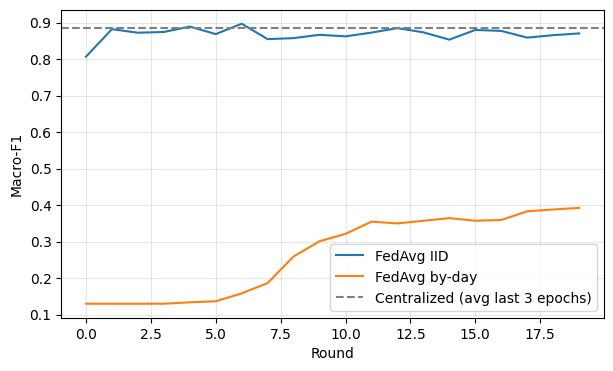

In [12]:
from sklearn.metrics import recall_score
import matplotlib.pyplot as plt

cent_recall = recall_score(y_test, predict(model, Xte), average=None,
                           labels=range(N_CLS), zero_division=0)

tab = pd.DataFrame({
    "Centralized": cent_recall,
    "FedAvg-IID":  hist_iid[-1]["recall"],
    "FedAvg-Day":  hist_day[-1]["recall"],
}, index=classes).round(3)
print(tab)

# convergence curves
plt.figure(figsize=(7,4))
plt.plot([h["macro_f1"] for h in hist_iid], label="FedAvg IID")
plt.plot([h["macro_f1"] for h in hist_day], label="FedAvg by-day")
plt.axhline(0.886, ls="--", c="gray", label="Centralized (avg last 3 epochs)")
plt.xlabel("Round"); plt.ylabel("Macro-F1"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("convergence.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
import pickle
results = {}

def save_results():
    with open("/content/data/results.pkl", "wb") as f:
        pickle.dump(results, f)

def last3(h):
    return np.mean([x["macro_f1"] for x in h[-3:]])

In [14]:
# FedAvg by-day, longer
_, results["day_fedavg"] = run_fl(parts_day, rounds=40, mu=0.0, name="Day-FedAvg")
save_results(); print("last3 macroF1:", last3(results["day_fedavg"]))

[Day-FedAvg] round  1  acc 0.8296  macroF1 0.1296  (18s)
[Day-FedAvg] round  2  acc 0.8296  macroF1 0.1296  (18s)
[Day-FedAvg] round  3  acc 0.8296  macroF1 0.1296  (11s)
[Day-FedAvg] round  4  acc 0.8296  macroF1 0.1296  (11s)
[Day-FedAvg] round  5  acc 0.8301  macroF1 0.1334  (12s)
[Day-FedAvg] round  6  acc 0.8305  macroF1 0.1362  (12s)
[Day-FedAvg] round  7  acc 0.8346  macroF1 0.1580  (14s)
[Day-FedAvg] round  8  acc 0.8403  macroF1 0.1863  (12s)
[Day-FedAvg] round  9  acc 0.8623  macroF1 0.2592  (12s)
[Day-FedAvg] round 10  acc 0.8791  macroF1 0.3008  (11s)
[Day-FedAvg] round 11  acc 0.8799  macroF1 0.3211  (12s)
[Day-FedAvg] round 12  acc 0.9005  macroF1 0.3545  (13s)
[Day-FedAvg] round 13  acc 0.8932  macroF1 0.3497  (13s)
[Day-FedAvg] round 14  acc 0.8962  macroF1 0.3569  (13s)
[Day-FedAvg] round 15  acc 0.8997  macroF1 0.3642  (15s)
[Day-FedAvg] round 16  acc 0.8918  macroF1 0.3570  (15s)
[Day-FedAvg] round 17  acc 0.8966  macroF1 0.3591  (18s)
[Day-FedAvg] round 18  acc 0.90

In [15]:
# FedProx by-day, mu = 0.01
_, results["day_prox_0.01"] = run_fl(parts_day, rounds=40, mu=0.01, name="Day-Prox0.01")
save_results(); print("last3 macroF1:", last3(results["day_prox_0.01"]))

[Day-Prox0.01] round  1  acc 0.8296  macroF1 0.1296  (16s)
[Day-Prox0.01] round  2  acc 0.8296  macroF1 0.1296  (14s)
[Day-Prox0.01] round  3  acc 0.8296  macroF1 0.1296  (13s)
[Day-Prox0.01] round  4  acc 0.8301  macroF1 0.1337  (12s)
[Day-Prox0.01] round  5  acc 0.8527  macroF1 0.2301  (13s)
[Day-Prox0.01] round  6  acc 0.8856  macroF1 0.3340  (14s)
[Day-Prox0.01] round  7  acc 0.9134  macroF1 0.3967  (14s)
[Day-Prox0.01] round  8  acc 0.9272  macroF1 0.4311  (15s)
[Day-Prox0.01] round  9  acc 0.9292  macroF1 0.4353  (16s)
[Day-Prox0.01] round 10  acc 0.9407  macroF1 0.4621  (15s)
[Day-Prox0.01] round 11  acc 0.9487  macroF1 0.4832  (15s)
[Day-Prox0.01] round 12  acc 0.9491  macroF1 0.4814  (14s)
[Day-Prox0.01] round 13  acc 0.9551  macroF1 0.5004  (15s)
[Day-Prox0.01] round 14  acc 0.9557  macroF1 0.4989  (15s)
[Day-Prox0.01] round 15  acc 0.9606  macroF1 0.5082  (15s)
[Day-Prox0.01] round 16  acc 0.9643  macroF1 0.5196  (14s)
[Day-Prox0.01] round 17  acc 0.9658  macroF1 0.5218  (14

In [16]:
# FedProx by-day, mu = 0.1
_, results["day_prox_0.1"] = run_fl(parts_day, rounds=40, mu=0.1, name="Day-Prox0.1")
save_results(); print("last3 macroF1:", last3(results["day_prox_0.1"]))

[Day-Prox0.1] round  1  acc 0.8296  macroF1 0.1296  (16s)
[Day-Prox0.1] round  2  acc 0.8296  macroF1 0.1296  (13s)
[Day-Prox0.1] round  3  acc 0.8296  macroF1 0.1296  (13s)
[Day-Prox0.1] round  4  acc 0.8296  macroF1 0.1296  (13s)
[Day-Prox0.1] round  5  acc 0.8365  macroF1 0.1656  (13s)
[Day-Prox0.1] round  6  acc 0.8699  macroF1 0.2788  (16s)
[Day-Prox0.1] round  7  acc 0.8821  macroF1 0.3239  (14s)
[Day-Prox0.1] round  8  acc 0.9015  macroF1 0.3821  (13s)
[Day-Prox0.1] round  9  acc 0.9182  macroF1 0.4316  (14s)
[Day-Prox0.1] round 10  acc 0.9338  macroF1 0.5129  (13s)
[Day-Prox0.1] round 11  acc 0.9469  macroF1 0.5403  (13s)
[Day-Prox0.1] round 12  acc 0.9472  macroF1 0.5403  (14s)
[Day-Prox0.1] round 13  acc 0.9499  macroF1 0.5485  (13s)
[Day-Prox0.1] round 14  acc 0.9472  macroF1 0.5357  (13s)
[Day-Prox0.1] round 15  acc 0.9613  macroF1 0.5978  (13s)
[Day-Prox0.1] round 16  acc 0.9660  macroF1 0.6192  (13s)
[Day-Prox0.1] round 17  acc 0.9700  macroF1 0.6394  (13s)
[Day-Prox0.1] 

            Centralized  IID-FedAvg  Day-FedAvg  Day-Prox0.01  Day-Prox0.1
BENIGN            0.995       0.995       1.000         0.999        0.999
DoS               1.000       0.999       0.197         0.872        0.904
DDoS              1.000       1.000       0.671         0.994        0.996
PortScan          0.999       0.999       0.460         0.932        0.917
BruteForce        0.999       1.000       0.000         0.644        0.939
WebAttack         0.981       0.977       0.000         0.000        0.000
Bot               0.951       0.764       0.000         0.375        0.318


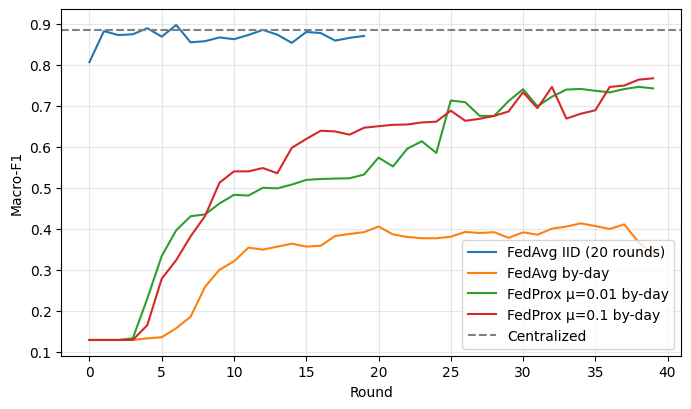

In [17]:
def rec3(h):
    return np.mean([x["recall"] for x in h[-3:]], axis=0)

tab = pd.DataFrame({
    "Centralized":    cent_recall,
    "IID-FedAvg":     rec3(hist_iid),
    "Day-FedAvg":     rec3(results["day_fedavg"]),
    "Day-Prox0.01":   rec3(results["day_prox_0.01"]),
    "Day-Prox0.1":    rec3(results["day_prox_0.1"]),
}, index=classes).round(3)
print(tab)

# convergence plot with all by-day runs
plt.figure(figsize=(8,4.5))
plt.plot([h["macro_f1"] for h in hist_iid], label="FedAvg IID (20 rounds)")
for key, lab in [("day_fedavg","FedAvg by-day"),
                 ("day_prox_0.01","FedProx μ=0.01 by-day"),
                 ("day_prox_0.1","FedProx μ=0.1 by-day")]:
    plt.plot([h["macro_f1"] for h in results[key]], label=lab)
plt.axhline(0.886, ls="--", c="gray", label="Centralized")
plt.xlabel("Round"); plt.ylabel("Macro-F1"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("convergence_all.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# (a) Is a stronger proximal term even better? Test mu = 1.0
_, results["day_prox_1.0"] = run_fl(parts_day, rounds=40, mu=1.0, name="Day-Prox1.0")
save_results(); print("last3 macroF1:", last3(results["day_prox_1.0"]))

[Day-Prox1.0] round  1  acc 0.8296  macroF1 0.1296  (19s)
[Day-Prox1.0] round  2  acc 0.8296  macroF1 0.1296  (15s)
[Day-Prox1.0] round  3  acc 0.8296  macroF1 0.1296  (16s)
[Day-Prox1.0] round  4  acc 0.8296  macroF1 0.1296  (15s)
[Day-Prox1.0] round  5  acc 0.8296  macroF1 0.1296  (14s)
[Day-Prox1.0] round  6  acc 0.8296  macroF1 0.1296  (14s)
[Day-Prox1.0] round  7  acc 0.8296  macroF1 0.1296  (15s)
[Day-Prox1.0] round  8  acc 0.8396  macroF1 0.1775  (14s)
[Day-Prox1.0] round  9  acc 0.8523  macroF1 0.2193  (14s)
[Day-Prox1.0] round 10  acc 0.8707  macroF1 0.2793  (14s)
[Day-Prox1.0] round 11  acc 0.8878  macroF1 0.3617  (14s)
[Day-Prox1.0] round 12  acc 0.9130  macroF1 0.4433  (15s)
[Day-Prox1.0] round 13  acc 0.9285  macroF1 0.5133  (14s)
[Day-Prox1.0] round 14  acc 0.9319  macroF1 0.5372  (15s)
[Day-Prox1.0] round 15  acc 0.9369  macroF1 0.5464  (14s)
[Day-Prox1.0] round 16  acc 0.9383  macroF1 0.5661  (14s)
[Day-Prox1.0] round 17  acc 0.9403  macroF1 0.5764  (14s)
[Day-Prox1.0] 

In [19]:
# (b) IID for the same 40 rounds, so all settings are comparable
_, results["iid_fedavg"] = run_fl(parts_iid, rounds=40, mu=0.0, name="IID-FedAvg40")
save_results(); print("last3 macroF1:", last3(results["iid_fedavg"]))

[IID-FedAvg40] round  1  acc 0.9874  macroF1 0.8066  (16s)
[IID-FedAvg40] round  2  acc 0.9952  macroF1 0.8821  (12s)
[IID-FedAvg40] round  3  acc 0.9957  macroF1 0.8724  (12s)
[IID-FedAvg40] round  4  acc 0.9953  macroF1 0.8744  (10s)
[IID-FedAvg40] round  5  acc 0.9962  macroF1 0.8892  (12s)
[IID-FedAvg40] round  6  acc 0.9948  macroF1 0.8686  (12s)
[IID-FedAvg40] round  7  acc 0.9963  macroF1 0.8970  (12s)
[IID-FedAvg40] round  8  acc 0.9924  macroF1 0.8547  (11s)
[IID-FedAvg40] round  9  acc 0.9919  macroF1 0.8576  (11s)
[IID-FedAvg40] round 10  acc 0.9945  macroF1 0.8667  (13s)
[IID-FedAvg40] round 11  acc 0.9944  macroF1 0.8624  (12s)
[IID-FedAvg40] round 12  acc 0.9961  macroF1 0.8727  (12s)
[IID-FedAvg40] round 13  acc 0.9954  macroF1 0.8850  (11s)
[IID-FedAvg40] round 14  acc 0.9951  macroF1 0.8734  (11s)
[IID-FedAvg40] round 15  acc 0.9930  macroF1 0.8534  (12s)
[IID-FedAvg40] round 16  acc 0.9955  macroF1 0.8799  (12s)
[IID-FedAvg40] round 17  acc 0.9954  macroF1 0.8774  (12

In [20]:
# (c) A second seed for FedAvg and your best FedProx (checks the 0.37 vs 0.76 gap is not luck)
_, results["day_fedavg_s1"]   = run_fl(parts_day, rounds=40, mu=0.0, seed=1, name="Day-FedAvg-s1")
save_results(); print(last3(results["day_fedavg_s1"]))

[Day-FedAvg-s1] round  1  acc 0.8296  macroF1 0.1296  (16s)
[Day-FedAvg-s1] round  2  acc 0.8296  macroF1 0.1296  (11s)
[Day-FedAvg-s1] round  3  acc 0.8296  macroF1 0.1296  (12s)
[Day-FedAvg-s1] round  4  acc 0.8296  macroF1 0.1296  (12s)
[Day-FedAvg-s1] round  5  acc 0.8336  macroF1 0.1453  (11s)
[Day-FedAvg-s1] round  6  acc 0.8406  macroF1 0.1742  (10s)
[Day-FedAvg-s1] round  7  acc 0.8372  macroF1 0.1663  (14s)
[Day-FedAvg-s1] round  8  acc 0.8525  macroF1 0.2167  (13s)
[Day-FedAvg-s1] round  9  acc 0.8527  macroF1 0.2310  (12s)
[Day-FedAvg-s1] round 10  acc 0.8794  macroF1 0.2979  (12s)
[Day-FedAvg-s1] round 11  acc 0.8746  macroF1 0.2908  (11s)
[Day-FedAvg-s1] round 12  acc 0.8851  macroF1 0.3138  (11s)
[Day-FedAvg-s1] round 13  acc 0.8878  macroF1 0.3207  (12s)
[Day-FedAvg-s1] round 14  acc 0.9031  macroF1 0.3675  (12s)
[Day-FedAvg-s1] round 15  acc 0.8955  macroF1 0.3547  (13s)
[Day-FedAvg-s1] round 16  acc 0.8957  macroF1 0.3470  (14s)
[Day-FedAvg-s1] round 17  acc 0.9126  ma

In [21]:
_, results["day_prox_0.1_s1"] = run_fl(parts_day, rounds=40, mu=0.1, seed=1, name="Day-Prox0.1-s1")
save_results(); print(last3(results["day_prox_0.1_s1"]))

[Day-Prox0.1-s1] round  1  acc 0.8296  macroF1 0.1296  (18s)
[Day-Prox0.1-s1] round  2  acc 0.8296  macroF1 0.1296  (14s)
[Day-Prox0.1-s1] round  3  acc 0.8296  macroF1 0.1296  (13s)
[Day-Prox0.1-s1] round  4  acc 0.8302  macroF1 0.1333  (13s)
[Day-Prox0.1-s1] round  5  acc 0.8462  macroF1 0.2014  (13s)
[Day-Prox0.1-s1] round  6  acc 0.8657  macroF1 0.2652  (14s)
[Day-Prox0.1-s1] round  7  acc 0.8819  macroF1 0.3285  (15s)
[Day-Prox0.1-s1] round  8  acc 0.9209  macroF1 0.4280  (15s)
[Day-Prox0.1-s1] round  9  acc 0.9360  macroF1 0.4623  (14s)
[Day-Prox0.1-s1] round 10  acc 0.9408  macroF1 0.4690  (15s)
[Day-Prox0.1-s1] round 11  acc 0.9520  macroF1 0.5506  (15s)
[Day-Prox0.1-s1] round 12  acc 0.9505  macroF1 0.5403  (15s)
[Day-Prox0.1-s1] round 13  acc 0.9594  macroF1 0.5635  (13s)
[Day-Prox0.1-s1] round 14  acc 0.9574  macroF1 0.5524  (14s)
[Day-Prox0.1-s1] round 15  acc 0.9637  macroF1 0.6076  (12s)
[Day-Prox0.1-s1] round 16  acc 0.9707  macroF1 0.6325  (14s)
[Day-Prox0.1-s1] round 1

In [22]:
parts_dir = {}
for a in [0.1, 0.5, 1.0]:
    parts_dir[a] = partition_dirichlet(y_train, K, alpha=a, seed=0)
    show_partition(parts_dir[a], f"Dirichlet alpha={a}")


Dirichlet alpha=0.1
          BENIGN     DoS    DDoS  PortScan  BruteForce  WebAttack   Bot
client0     1670  137572  102407     59725           0        122    24
client1        0       5       3      1526           0          0     2
client2       18    1433       0     11276           0          0   268
client3  1656114       0       0        16           1       1591  1264
client4        1   15974       1        12        7319          1     1

Dirichlet alpha=0.5
         BENIGN    DoS   DDoS  PortScan  BruteForce  WebAttack   Bot
client0  607012   6256   6238      3149        1405          5   252
client1    9351  19087  13638     19646         915        355  1077
client2  245080   1285   2746       259        2561        482   206
client3   14033  30959  68566     47185         546         84    22
client4  782327  97397  11223      2316        1893        788     2

Dirichlet alpha=1.0
         BENIGN    DoS   DDoS  PortScan  BruteForce  WebAttack  Bot
client0  460383  21202 

In [23]:
for a in [0.1, 0.5, 1.0]:
    _, results[f"dir{a}_fedavg"] = run_fl(parts_dir[a], rounds=40, mu=0.0, name=f"Dir{a}-FedAvg")
    save_results(); print(a, "FedAvg last3:", last3(results[f"dir{a}_fedavg"]))

[Dir0.1-FedAvg] round  1  acc 0.8305  macroF1 0.3355  (18s)
[Dir0.1-FedAvg] round  2  acc 0.8289  macroF1 0.2709  (18s)
[Dir0.1-FedAvg] round  3  acc 0.8294  macroF1 0.2706  (13s)
[Dir0.1-FedAvg] round  4  acc 0.8372  macroF1 0.2887  (13s)
[Dir0.1-FedAvg] round  5  acc 0.8416  macroF1 0.3511  (19s)
[Dir0.1-FedAvg] round  6  acc 0.8516  macroF1 0.3798  (16s)
[Dir0.1-FedAvg] round  7  acc 0.8462  macroF1 0.3715  (18s)
[Dir0.1-FedAvg] round  8  acc 0.8463  macroF1 0.3598  (16s)
[Dir0.1-FedAvg] round  9  acc 0.8524  macroF1 0.3790  (19s)
[Dir0.1-FedAvg] round 10  acc 0.8459  macroF1 0.3595  (28s)
[Dir0.1-FedAvg] round 11  acc 0.8468  macroF1 0.3627  (41s)
[Dir0.1-FedAvg] round 12  acc 0.8540  macroF1 0.3983  (52s)
[Dir0.1-FedAvg] round 13  acc 0.8547  macroF1 0.3769  (67s)
[Dir0.1-FedAvg] round 14  acc 0.8453  macroF1 0.3617  (41s)
[Dir0.1-FedAvg] round 15  acc 0.8572  macroF1 0.4280  (25s)
[Dir0.1-FedAvg] round 16  acc 0.8530  macroF1 0.3726  (22s)
[Dir0.1-FedAvg] round 17  acc 0.8537  ma

In [24]:
for a in [0.1, 0.5, 1.0]:
    _, results[f"dir{a}_prox"] = run_fl(parts_dir[a], rounds=40, mu=0.1, name=f"Dir{a}-Prox")
    save_results(); print(a, "FedProx last3:", last3(results[f"dir{a}_prox"]))

[Dir0.1-Prox] round  1  acc 0.8266  macroF1 0.1674  (22s)
[Dir0.1-Prox] round  2  acc 0.8234  macroF1 0.1529  (15s)
[Dir0.1-Prox] round  3  acc 0.8223  macroF1 0.2160  (15s)
[Dir0.1-Prox] round  4  acc 0.8257  macroF1 0.2342  (16s)
[Dir0.1-Prox] round  5  acc 0.8255  macroF1 0.2341  (14s)
[Dir0.1-Prox] round  6  acc 0.8257  macroF1 0.2375  (14s)
[Dir0.1-Prox] round  7  acc 0.8011  macroF1 0.1636  (13s)
[Dir0.1-Prox] round  8  acc 0.8267  macroF1 0.2398  (13s)
[Dir0.1-Prox] round  9  acc 0.8227  macroF1 0.1986  (14s)
[Dir0.1-Prox] round 10  acc 0.8256  macroF1 0.2141  (14s)
[Dir0.1-Prox] round 11  acc 0.8252  macroF1 0.2196  (14s)
[Dir0.1-Prox] round 12  acc 0.8282  macroF1 0.2410  (14s)
[Dir0.1-Prox] round 13  acc 0.8279  macroF1 0.2454  (13s)
[Dir0.1-Prox] round 14  acc 0.8263  macroF1 0.2367  (14s)
[Dir0.1-Prox] round 15  acc 0.8264  macroF1 0.2410  (14s)
[Dir0.1-Prox] round 16  acc 0.8260  macroF1 0.2347  (13s)
[Dir0.1-Prox] round 17  acc 0.8293  macroF1 0.2826  (14s)
[Dir0.1-Prox] 

                 last3_macroF1  std_last10  final_acc
run                                                  
iid_fedavg               0.872       0.011      0.995
dir1.0_fedavg            0.870       0.011      0.995
dir1.0_prox              0.912       0.010      0.996
dir0.5_fedavg            0.906       0.007      0.998
dir0.5_prox              0.919       0.007      0.997
dir0.1_fedavg            0.399       0.033      0.850
dir0.1_prox              0.421       0.039      0.878
day_fedavg               0.372       0.022      0.884
day_fedavg_s1            0.265       0.028      0.859
day_prox_0.01            0.743       0.013      0.984
day_prox_0.1             0.760       0.035      0.988
day_prox_0.1_s1          0.750       0.022      0.990
day_prox_1.0             0.638       0.009      0.972

             Centralized  iid_fedavg  dir0.1_fedavg  dir0.1_prox  day_fedavg  \
BENIGN            0.995       0.994          0.995        0.998       1.000   
DoS               1.000       

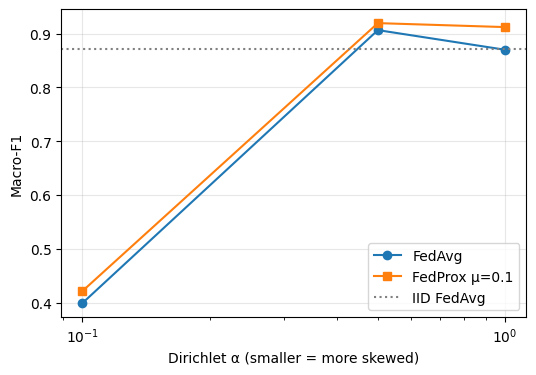

In [25]:
keys = ["iid_fedavg",
        "dir1.0_fedavg","dir1.0_prox","dir0.5_fedavg","dir0.5_prox",
        "dir0.1_fedavg","dir0.1_prox",
        "day_fedavg","day_fedavg_s1","day_prox_0.01","day_prox_0.1",
        "day_prox_0.1_s1","day_prox_1.0"]

rows = []
for k in keys:
    f1s = [h["macro_f1"] for h in results[k]]
    rows.append({"run": k,
                 "last3_macroF1": np.mean(f1s[-3:]),
                 "std_last10": np.std(f1s[-10:]),      # round-to-round noise
                 "final_acc": results[k][-1]["acc"]})
summary = pd.DataFrame(rows).set_index("run").round(3)
print(summary)
summary.to_csv("/content/data/summary.csv")

# per-class recall (average of last 3 rounds)
sel = ["iid_fedavg", "dir0.1_fedavg", "dir0.1_prox", "day_fedavg", "day_prox_0.1"]
recall_tab = pd.DataFrame({k: rec3(results[k]) for k in sel}, index=classes).round(3)
recall_tab.insert(0, "Centralized", cent_recall.round(3))
print("\n", recall_tab)

# hypothesis check: share of FedAvg weight per client
for name, parts in [("Dirichlet 0.1", parts_dir[0.1]), ("By day", parts_day)]:
    sizes = np.array([len(p) for p in parts])
    print(name, "client weight share:", (sizes / sizes.sum()).round(3))

# macro-F1 vs alpha
alphas = [0.1, 0.5, 1.0]
plt.figure(figsize=(6, 4))
plt.plot(alphas, [last3(results[f"dir{a}_fedavg"]) for a in alphas], "o-", label="FedAvg")
plt.plot(alphas, [last3(results[f"dir{a}_prox"]) for a in alphas], "s-", label="FedProx μ=0.1")
plt.axhline(last3(results["iid_fedavg"]), ls=":", c="gray", label="IID FedAvg")
plt.xscale("log"); plt.xlabel("Dirichlet α (smaller = more skewed)")
plt.ylabel("Macro-F1"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("macro_f1_vs_alpha.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
for a in [0.2, 0.3]:
    parts_dir[a] = partition_dirichlet(y_train, K, alpha=a, seed=0)
    _, results[f"dir{a}_fedavg"] = run_fl(parts_dir[a], rounds=40, mu=0.0, name=f"Dir{a}-FedAvg")
    save_results(); print(a, "FedAvg last3:", last3(results[f"dir{a}_fedavg"]))

for a in [0.2, 0.3]:
    _, results[f"dir{a}_prox"] = run_fl(parts_dir[a], rounds=40, mu=0.1, name=f"Dir{a}-Prox")
    save_results(); print(a, "FedProx last3:", last3(results[f"dir{a}_prox"]))

_, results["iid_prox"] = run_fl(parts_iid, rounds=40, mu=0.1, name="IID-Prox")
save_results(); print("IID FedProx last3:", last3(results["iid_prox"]))

[Dir0.2-FedAvg] round  1  acc 0.9342  macroF1 0.6078  (19s)
[Dir0.2-FedAvg] round  2  acc 0.9650  macroF1 0.7475  (11s)
[Dir0.2-FedAvg] round  3  acc 0.9927  macroF1 0.8788  (13s)
[Dir0.2-FedAvg] round  4  acc 0.9933  macroF1 0.8698  (12s)
[Dir0.2-FedAvg] round  5  acc 0.9941  macroF1 0.8413  (14s)
[Dir0.2-FedAvg] round  6  acc 0.9958  macroF1 0.9076  (13s)
[Dir0.2-FedAvg] round  7  acc 0.9947  macroF1 0.8284  (14s)
[Dir0.2-FedAvg] round  8  acc 0.9964  macroF1 0.8967  (13s)
[Dir0.2-FedAvg] round  9  acc 0.9968  macroF1 0.9069  (12s)
[Dir0.2-FedAvg] round 10  acc 0.9951  macroF1 0.8485  (13s)
[Dir0.2-FedAvg] round 11  acc 0.9943  macroF1 0.8423  (14s)
[Dir0.2-FedAvg] round 12  acc 0.9947  macroF1 0.8554  (15s)
[Dir0.2-FedAvg] round 13  acc 0.9927  macroF1 0.8604  (16s)
[Dir0.2-FedAvg] round 14  acc 0.9938  macroF1 0.8400  (17s)
[Dir0.2-FedAvg] round 15  acc 0.9963  macroF1 0.8887  (19s)
[Dir0.2-FedAvg] round 16  acc 0.9956  macroF1 0.8686  (19s)
[Dir0.2-FedAvg] round 17  acc 0.9951  ma

In [1]:
# 1. in the function signature, add a parameter:
def run_fl(parts, rounds=20, local_epochs=1, lr=1e-3, mu=0.0, bs=1024, seed=42, name="", uniform=False):

# 2. replace the line   wk = len(cy) / total
wk = (1.0 / len(clients)) if uniform else (len(cy) / total)

IndentationError: expected an indented block after function definition on line 2 (2051795067.py, line 5)

In [2]:
import os
for p in ["/content/data/prep", "/content/data/results.pkl", "/content/data/cicids_clean.parquet"]:
    print(p, "->", "EXISTS" if os.path.exists(p) else "MISSING")

/content/data/prep -> MISSING
/content/data/results.pkl -> MISSING
/content/data/cicids_clean.parquet -> MISSING


In [3]:
from google.colab import drive
drive.mount("/content/drive")

import os, glob, zipfile, shutil
import numpy as np, pandas as pd
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split

DATA = "/content/data"
os.makedirs(DATA, exist_ok=True)

# ---- download and extract
zip_path = hf_hub_download(repo_id="bencorn/CICIDS2017", repo_type="dataset",
                           filename="csvs/MachineLearningCSV.zip", local_dir=DATA)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(DATA)

# ---- load and clean (same as before)
csvs = sorted(glob.glob(f"{DATA}/**/*.csv", recursive=True))
print(len(csvs), "csv files")
frames = []
for f in csvs:
    d = pd.read_csv(f, encoding="cp1252", low_memory=False)
    d.columns = d.columns.str.strip()
    d["day"] = os.path.basename(f).split("-")[0]
    frames.append(d)
data = pd.concat(frames, ignore_index=True); del frames

if "Fwd Header Length.1" in data.columns:
    data = data.drop(columns=["Fwd Header Length.1"])
data["Label"] = (data["Label"]
                 .str.replace(r"[^\x00-\x7F]+", "-", regex=True)
                 .str.replace(r"\s*-\s*", " - ", regex=True)
                 .str.strip())
feat_cols = [c for c in data.columns if c not in ("Label", "day")]
data[feat_cols] = data[feat_cols].replace([np.inf, -np.inf], np.nan).astype("float32")
data = data.dropna().reset_index(drop=True)
data = data.drop_duplicates(subset=feat_cols + ["Label"]).reset_index(drop=True)

# ---- group classes (same mapping as before)
label_map = {
    "BENIGN": "BENIGN",
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
    "DDoS": "DDoS", "PortScan": "PortScan",
    "FTP - Patator": "BruteForce", "SSH - Patator": "BruteForce",
    "Web Attack - Brute Force": "WebAttack", "Web Attack - XSS": "WebAttack",
    "Web Attack - Sql Injection": "WebAttack", "Bot": "Bot",
}
classes = ["BENIGN", "DoS", "DDoS", "PortScan", "BruteForce", "WebAttack", "Bot"]
cls2id = {c: i for i, c in enumerate(classes)}
df = data[data["Label"].isin(label_map)].copy()
del data
df["y"] = df["Label"].map(label_map).map(cls2id).astype("int64")
print("Rows after grouping:", len(df), "(expected 2,497,933)")

# ---- transform, split, scale (same seed and procedure)
X = df[feat_cols].values.astype(np.float32)
y = df["y"].values
day = df["day"].values
X = np.sign(X) * np.log1p(np.abs(X))

idx = np.arange(len(df))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=42)
mu = X[tr_idx].mean(axis=0)
sd = X[tr_idx].std(axis=0); sd[sd < 1e-6] = 1.0
X -= mu; X /= sd
np.clip(X, -10, 10, out=X)

prep = f"{DATA}/prep"; os.makedirs(prep, exist_ok=True)
for name, arr in dict(X_train=X[tr_idx], y_train=y[tr_idx], day_train=day[tr_idx],
                      X_test=X[te_idx], y_test=y[te_idx]).items():
    np.save(f"{prep}/{name}.npy", arr)

# ---- back up to Drive
bk = "/content/drive/MyDrive/fl_ids"
os.makedirs(bk, exist_ok=True)
shutil.copytree(prep, f"{bk}/prep", dirs_exist_ok=True)

print("Train:", X[tr_idx].shape, " Test:", X[te_idx].shape)
print("Backed up to", bk)

Mounted at /content/drive


csvs/MachineLearningCSV.zip: reconstructing file:   0%|          |  0.00B /  235MB            

csvs/MachineLearningCSV.zip: downloading bytes:           |  0.00B            

8 csv files
Rows after grouping: 2497933 (expected 2,497,933)
Train: (1998346, 77)  Test: (499587, 77)
Backed up to /content/drive/MyDrive/fl_ids


In [4]:
import os, copy, time, pickle
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, recall_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

classes = ["BENIGN", "DoS", "DDoS", "PortScan", "BruteForce", "WebAttack", "Bot"]
P = "/content/data/prep"
X_train = np.load(f"{P}/X_train.npy"); y_train = np.load(f"{P}/y_train.npy")
day_train = np.load(f"{P}/day_train.npy", allow_pickle=True)
X_test = np.load(f"{P}/X_test.npy");  y_test = np.load(f"{P}/y_test.npy")
N_FEAT, N_CLS = X_train.shape[1], len(classes)

def make_model():
    return nn.Sequential(nn.Linear(N_FEAT, 128), nn.ReLU(),
                         nn.Linear(128, 64), nn.ReLU(),
                         nn.Linear(64, N_CLS))

counts = np.bincount(y_train, minlength=N_CLS).astype(np.float64)
w = np.sqrt(counts.sum() / counts); w = w / w.mean()
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

@torch.no_grad()
def predict(model, X, bs=8192):
    model.eval()
    return torch.cat([model(X[i:i+bs]).argmax(1).cpu() for i in range(0, len(X), bs)]).numpy()

Xtr = torch.from_numpy(X_train).to(device); ytr = torch.from_numpy(y_train).to(device)
Xte = torch.from_numpy(X_test).to(device)

# ---- partitioners (same code and seeds as before)
def partition_iid(n, k, seed=0):
    rng = np.random.default_rng(seed)
    return np.array_split(rng.permutation(n), k)

def partition_by_day(day_arr):
    return [np.where(day_arr == d)[0] for d in ["Monday","Tuesday","Wednesday","Thursday","Friday"]]

def partition_dirichlet(y, k, alpha, seed=0, min_size=50):
    rng = np.random.default_rng(seed)
    while True:
        parts = [[] for _ in range(k)]
        for c in range(N_CLS):
            idx_c = np.where(y == c)[0]; rng.shuffle(idx_c)
            p = rng.dirichlet([alpha] * k)
            cuts = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
            for i, chunk in enumerate(np.split(idx_c, cuts)):
                parts[i].extend(chunk.tolist())
        if min(len(p) for p in parts) >= min_size:
            break
    return [np.array(p) for p in parts]

K = 5
parts_iid = partition_iid(len(y_train), K)
parts_day = partition_by_day(day_train)
parts_dir = {a: partition_dirichlet(y_train, K, a, seed=0) for a in [0.1, 0.5, 1.0]}

# ---- FL loop (with uniform=True option)
def run_fl(parts, rounds=20, local_epochs=1, lr=1e-3, mu=0.0, bs=1024, seed=42,
           name="", uniform=False):
    torch.manual_seed(seed); np.random.seed(seed)
    gmodel = make_model().to(device)
    clients = []
    for p in parts:
        if len(p) == 0: continue
        pi = torch.from_numpy(p).to(device)
        clients.append((Xtr[pi], ytr[pi]))
    total = sum(len(cy) for _, cy in clients)
    history = []
    for r in range(1, rounds + 1):
        t0 = time.time()
        gparams = [p.detach().clone() for p in gmodel.parameters()]
        new_state = None
        for cX, cy in clients:
            m = copy.deepcopy(gmodel)
            opt = torch.optim.Adam(m.parameters(), lr=lr)
            for _ in range(local_epochs):
                m.train()
                perm = torch.randperm(len(cX), device=device)
                for i in range(0, len(cX), bs):
                    b = perm[i:i + bs]
                    opt.zero_grad()
                    loss = loss_fn(m(cX[b]), cy[b])
                    if mu > 0:
                        prox = sum(((p - g) ** 2).sum() for p, g in zip(m.parameters(), gparams))
                        loss = loss + (mu / 2) * prox
                    loss.backward();

Device: cpu


In [5]:
  import os, copy, time, pickle
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, recall_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

classes = ["BENIGN", "DoS", "DDoS", "PortScan", "BruteForce", "WebAttack", "Bot"]
P = "/content/data/prep"
X_train = np.load(f"{P}/X_train.npy"); y_train = np.load(f"{P}/y_train.npy")
day_train = np.load(f"{P}/day_train.npy", allow_pickle=True)
X_test = np.load(f"{P}/X_test.npy");  y_test = np.load(f"{P}/y_test.npy")
N_FEAT, N_CLS = X_train.shape[1], len(classes)

def make_model():
    return nn.Sequential(nn.Linear(N_FEAT, 128), nn.ReLU(),
                         nn.Linear(128, 64), nn.ReLU(),
                         nn.Linear(64, N_CLS))

counts = np.bincount(y_train, minlength=N_CLS).astype(np.float64)
w = np.sqrt(counts.sum() / counts); w = w / w.mean()
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))

@torch.no_grad()
def predict(model, X, bs=8192):
    model.eval()
    return torch.cat([model(X[i:i+bs]).argmax(1).cpu() for i in range(0, len(X), bs)]).numpy()

Xtr = torch.from_numpy(X_train).to(device); ytr = torch.from_numpy(y_train).to(device)
Xte = torch.from_numpy(X_test).to(device)

# ---- partitioners (same code and seeds as before)
def partition_iid(n, k, seed=0):
    rng = np.random.default_rng(seed)
    return np.array_split(rng.permutation(n), k)

def partition_by_day(day_arr):
    return [np.where(day_arr == d)[0] for d in ["Monday","Tuesday","Wednesday","Thursday","Friday"]]

def partition_dirichlet(y, k, alpha, seed=0, min_size=50):
    rng = np.random.default_rng(seed)
    while True:
        parts = [[] for _ in range(k)]
        for c in range(N_CLS):
            idx_c = np.where(y == c)[0]; rng.shuffle(idx_c)
            p = rng.dirichlet([alpha] * k)
            cuts = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
            for i, chunk in enumerate(np.split(idx_c, cuts)):
                parts[i].extend(chunk.tolist())
        if min(len(p) for p in parts) >= min_size:
            break
    return [np.array(p) for p in parts]

K = 5
parts_iid = partition_iid(len(y_train), K)
parts_day = partition_by_day(day_train)
parts_dir = {a: partition_dirichlet(y_train, K, a, seed=0) for a in [0.1, 0.5, 1.0]}

# ---- FL loop (with uniform=True option)
def run_fl(parts, rounds=20, local_epochs=1, lr=1e-3, mu=0.0, bs=1024, seed=42,
           name="", uniform=False):
    torch.manual_seed(seed); np.random.seed(seed)
    gmodel = make_model().to(device)
    clients = []
    for p in parts:
        if len(p) == 0: continue
        pi = torch.from_numpy(p).to(device)
        clients.append((Xtr[pi], ytr[pi]))
    total = sum(len(cy) for _, cy in clients)
    history = []
    for r in range(1, rounds + 1):
        t0 = time.time()
        gparams = [p.detach().clone() for p in gmodel.parameters()]
        new_state = None
        for cX, cy in clients:
            m = copy.deepcopy(gmodel)
            opt = torch.optim.Adam(m.parameters(), lr=lr)
            for _ in range(local_epochs):
                m.train()
                perm = torch.randperm(len(cX), device=device)
                for i in range(0, len(cX), bs):
                    b = perm[i:i + bs]
                    opt.zero_grad()
                    loss = loss_fn(m(cX[b]), cy[b])
                    if mu > 0:
                        prox = sum(((p - g) ** 2).sum() for p, g in zip(m.parameters(), gparams))
                        loss = loss + (mu / 2) * prox
                    loss.backward(); opt.step()
            wk = (1.0 / len(clients)) if uniform else (len(cy) / total)
            st = m.state_dict()
            if new_state is None:
                new_state = {k: v.clone() * wk for k, v in st.items()}
            else:
                for k in new_state: new_state[k] += st[k] * wk
        gmodel.load_state_dict(new_state)
        pred = predict(gmodel, Xte)
        acc = accuracy_score(y_test, pred)
        f1 = f1_score(y_test, pred, average="macro")
        rec = recall_score(y_test, pred, average=None, labels=range(N_CLS), zero_division=0)
        history.append({"round": r, "acc": acc, "macro_f1": f1, "recall": rec})
        print(f"[{name}] round {r:2d}  acc {acc:.4f}  macroF1 {f1:.4f}  ({time.time()-t0:.0f}s)")
    return gmodel, history

# ---- results (fresh, backed up to Drive after every run)
results = {}
def save_results():
    for path in ["/content/data/results.pkl", "/content/drive/MyDrive/fl_ids/results.pkl"]:
        with open(path, "wb") as f: pickle.dump(results, f)
def last3(h): return np.mean([x["macro_f1"] for x in h[-3:]])
def rec3(h):  return np.mean([x["recall"] for x in h[-3:]], axis=0)

# centralized per-class recall copied from your Step 6 report (that model was lost)
cent_recall = np.array([0.9954, 0.9997, 0.9998, 0.9992, 0.9989, 0.9814, 0.9512])

print("Train:", Xtr.shape, "Test:", Xte.shape)
print("Client sizes by day:", [len(p) for p in parts_day])
print("Client sizes Dirichlet 0.1:", [len(p) for p in parts_dir[0.1]])

Device: cpu
Train: torch.Size([1998346, 77]) Test: torch.Size([499587, 77])
Client sizes by day: [394181, 325422, 469162, 317306, 492275]
Client sizes Dirichlet 0.1: [301520, 1536, 12995, 1658986, 23309]


In [6]:
_, results["dir0.1_uniform"] = run_fl(parts_dir[0.1], rounds=40, mu=0.0,
                                      uniform=True, name="Dir0.1-Uniform")
save_results()
print("last3 macroF1:", last3(results["dir0.1_uniform"]))
print(dict(zip(classes, rec3(results["dir0.1_uniform"]).round(3))))

[Dir0.1-Uniform] round  1  acc 0.7319  macroF1 0.2876  (26s)
[Dir0.1-Uniform] round  2  acc 0.7116  macroF1 0.3623  (14s)
[Dir0.1-Uniform] round  3  acc 0.7089  macroF1 0.3242  (11s)
[Dir0.1-Uniform] round  4  acc 0.7286  macroF1 0.3224  (13s)
[Dir0.1-Uniform] round  5  acc 0.7737  macroF1 0.3492  (12s)
[Dir0.1-Uniform] round  6  acc 0.7952  macroF1 0.3572  (12s)
[Dir0.1-Uniform] round  7  acc 0.8185  macroF1 0.3694  (15s)
[Dir0.1-Uniform] round  8  acc 0.8229  macroF1 0.3723  (12s)
[Dir0.1-Uniform] round  9  acc 0.8389  macroF1 0.3880  (12s)
[Dir0.1-Uniform] round 10  acc 0.8469  macroF1 0.4451  (12s)
[Dir0.1-Uniform] round 11  acc 0.8614  macroF1 0.4968  (12s)
[Dir0.1-Uniform] round 12  acc 0.8653  macroF1 0.5055  (12s)
[Dir0.1-Uniform] round 13  acc 0.8785  macroF1 0.5301  (11s)
[Dir0.1-Uniform] round 14  acc 0.8898  macroF1 0.5497  (12s)
[Dir0.1-Uniform] round 15  acc 0.8918  macroF1 0.5534  (12s)
[Dir0.1-Uniform] round 16  acc 0.8934  macroF1 0.5695  (12s)
[Dir0.1-Uniform] round 1